In [1]:
import pandas as pd

file_path = "/Users/vaibhavbhatnagar/Desktop/DataScience-Project/ecommerce-customer-intelligence/E Commerce Dataset.xlsx"


df = pd.read_excel(
    file_path,
    sheet_name="E Comm"
)

df.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [2]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types and missing values:")
df.info()

Shape: (5630, 20)

Columns:
['CustomerID', 'Churn', 'Tenure', 'PreferredLoginDevice', 'CityTier', 'WarehouseToHome', 'PreferredPaymentMode', 'Gender', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']

Data types and missing values:
<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMod

In [3]:
missing = df.isnull().sum()

print(missing[missing > 0])

Tenure                         264
WarehouseToHome                251
HourSpendOnApp                 255
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
dtype: int64


In [4]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [5]:
print(df["Churn"].value_counts())

Churn
0    4682
1     948
Name: count, dtype: int64


In [6]:
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
0    83.161634
1    16.838366
Name: proportion, dtype: float64


# Exploratory Data Analysis (EDA)

In this section, we examine the dataset's structure, missing values, target distribution, and relationships between customer characteristics and churn.

In [7]:
df.describe()


,CustomerID,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
count,5630.000000,5630.000000,5366.000000,5630.000000,5379.000000,5375.000000,5630.000000,5630.000000,5630.000000,5630.000000,5365.000000,5374.000000,5372.000000,5323.000000,5630.000000
mean,52815.500000,0.168384,10.189899,1.654707,15.639896,2.931535,3.688988,3.066785,4.214032,0.284902,15.707922,1.751023,3.008004,4.543491,177.223030
std,1625.385339,0.374240,8.557241,0.915389,8.531475,0.721926,1.023999,1.380194,2.583586,0.451408,3.675485,1.894621,2.939680,3.654433,49.207036
min,50001.000000,0.000000,0.000000,1.000000,5.000000,0.000000,1.000000,1.000000,1.000000,0.000000,11.000000,0.000000,1.000000,0.000000,0.000000
25%,51408.250000,0.000000,2.000000,1.000000,9.000000,2.000000,3.000000,2.000000,2.000000,0.000000,13.000000,1.000000,1.000000,2.000000,145.770000
50%,52815.500000,0.000000,9.000000,1.000000,14.000000,3.000000,4.000000,3.000000,3.000000,0.000000,15.000000,1.000000,2.000000,3.000000,163.280000
75%,54222.750000,0.000000,16.000000,3.000000,20.000000,3.000000,4.000000,4.000000,6.000000,1.000000,18.000000,2.000000,3.000000,7.000000,196.392500
max,55630.000000,1.000000,61.000000,3.000000,127.000000,5.000000,6.000000,5.000000,22.000000,1.000000,26.000000,16.000000,16.000000,46.000000,324.990000


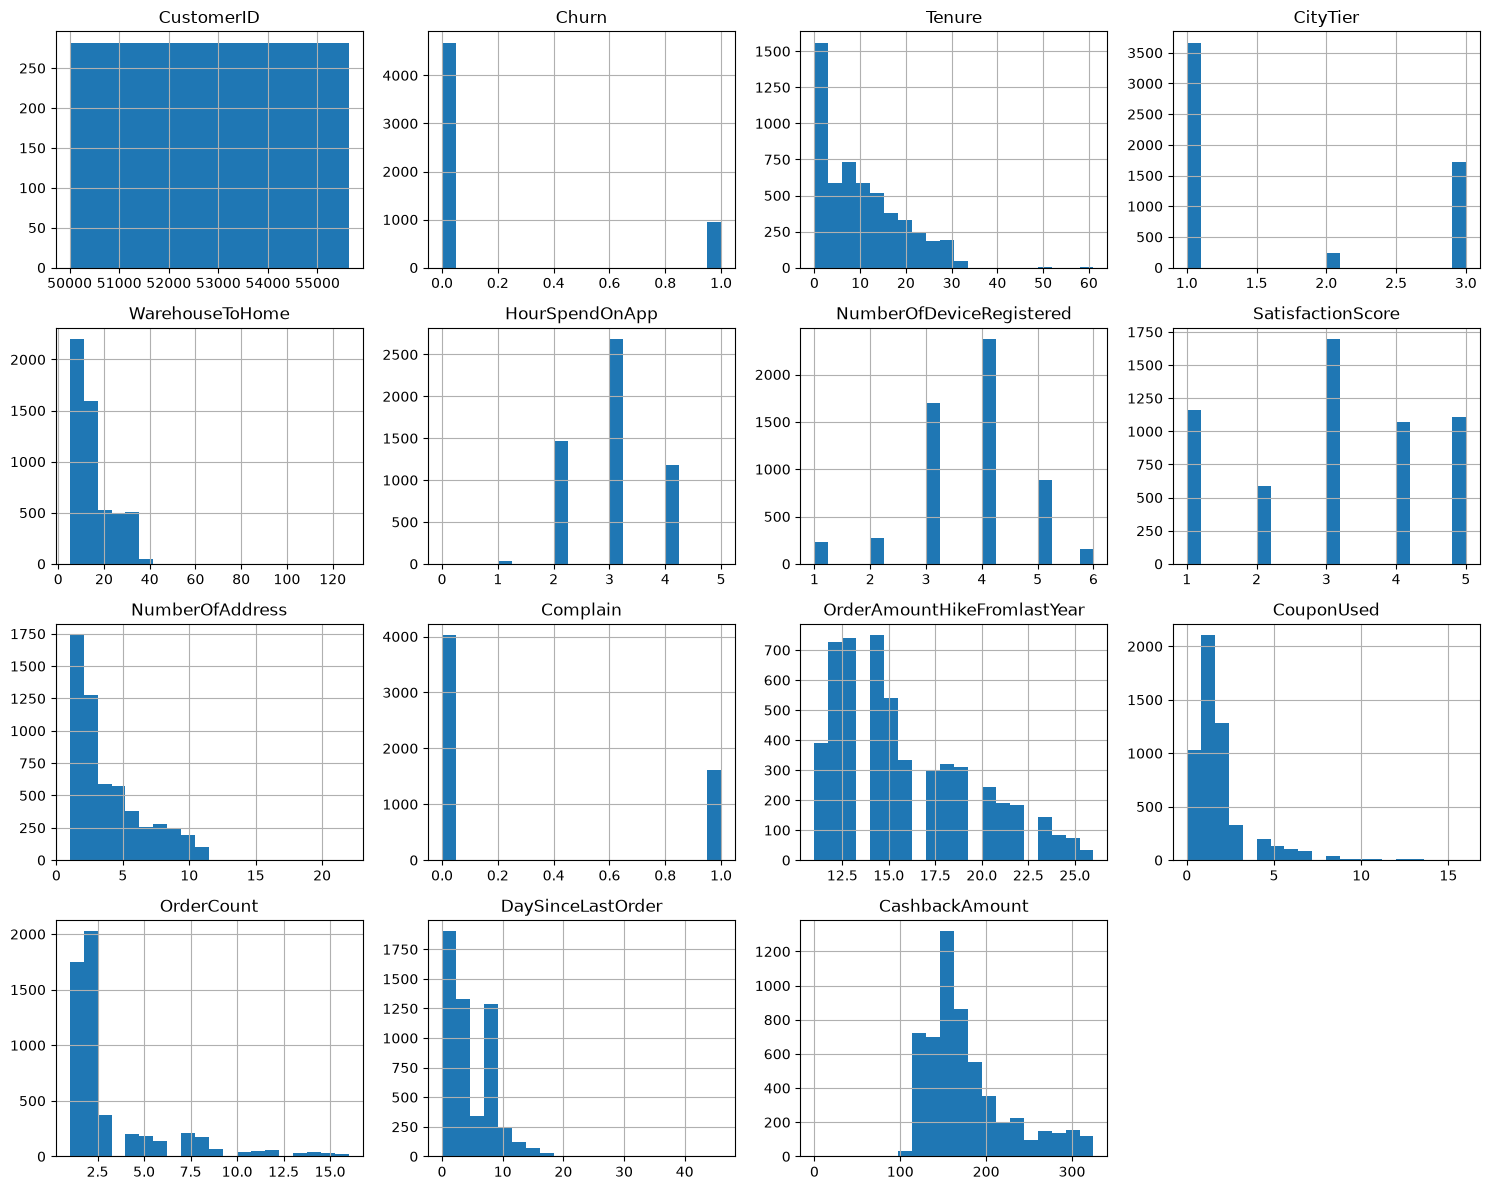

In [8]:
import matplotlib.pyplot as plt

df.hist(figsize=(15, 12), bins=20)

plt.tight_layout()
plt.show()

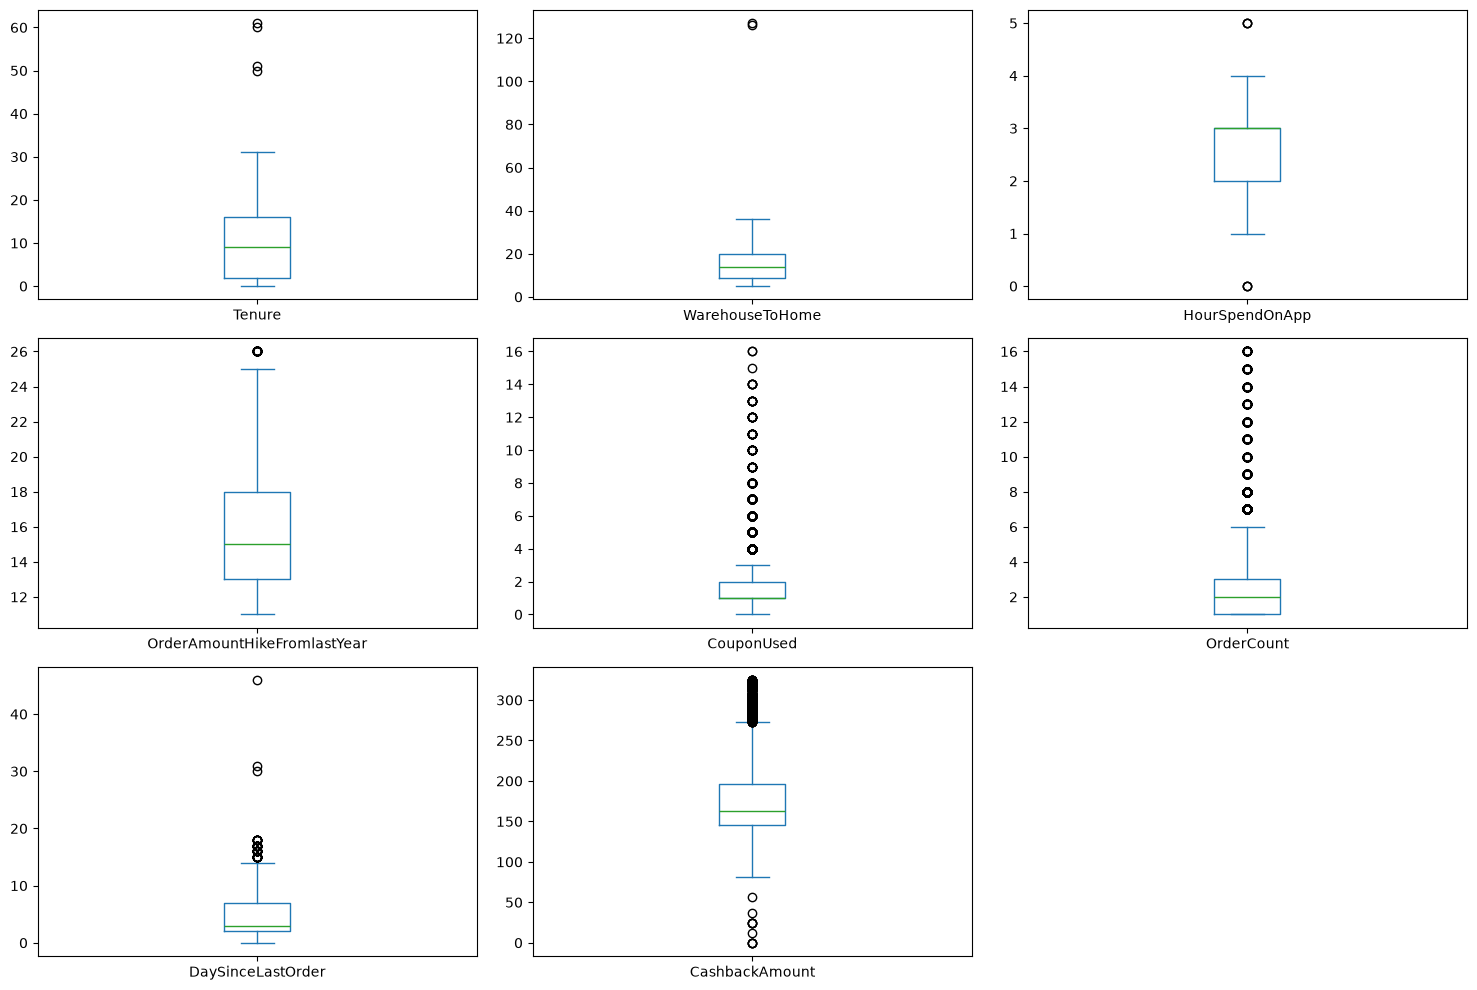

In [9]:
import matplotlib.pyplot as plt

numeric_columns = [
    "Tenure",
    "WarehouseToHome",
    "HourSpendOnApp",
    "OrderAmountHikeFromlastYear",
    "CouponUsed",
    "OrderCount",
    "DaySinceLastOrder",
    "CashbackAmount"
]

df[numeric_columns].plot(
    kind="box",
    subplots=True,
    layout=(3, 3),
    figsize=(15, 10)
)

plt.tight_layout()
plt.show()

In [10]:
df.groupby("Complain")["Churn"].mean() * 100

Complain
0    10.928962
1    31.670823
Name: Churn, dtype: float64

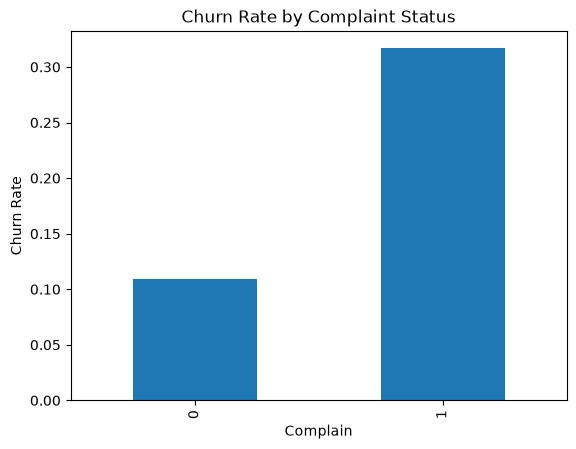

In [11]:
df.groupby("Complain")["Churn"].mean().plot(
    kind="bar",
    title="Churn Rate by Complaint Status"
)

plt.ylabel("Churn Rate")
plt.show()

In [12]:
df["Complain"].unique()

array([1, 0])

In [13]:
df["Complain"].value_counts()

Complain
0    4026
1    1604
Name: count, dtype: int64

In [14]:
df.groupby("SatisfactionScore")["Churn"].mean() * 100

SatisfactionScore
1    11.512027
2    12.627986
3    17.196702
4    17.132216
5    23.826715
Name: Churn, dtype: float64

In [15]:
df["SatisfactionScore"].value_counts().sort_index()

SatisfactionScore
1    1164
2     586
3    1698
4    1074
5    1108
Name: count, dtype: int64

In [16]:
df.groupby("CityTier")["Churn"].mean() * 100

CityTier
1    14.511729
2    19.834711
3    21.370499
Name: Churn, dtype: float64

In [17]:
df["CityTier"].value_counts().sort_index()

CityTier
1    3666
2     242
3    1722
Name: count, dtype: int64

In [18]:
df.groupby("PreferredLoginDevice")["Churn"].mean() * 100

PreferredLoginDevice
Computer        19.828641
Mobile Phone    12.585895
Phone           22.420796
Name: Churn, dtype: float64

In [19]:
df["PreferredLoginDevice"].value_counts()

PreferredLoginDevice
Mobile Phone    2765
Computer        1634
Phone           1231
Name: count, dtype: int64

In [20]:
df.groupby("PreferredPaymentMode")["Churn"].mean() * 100


PreferredPaymentMode
CC                  21.611722
COD                 28.767123
Cash on Delivery    15.436242
Credit Card         12.858095
Debit Card          15.384615
E wallet            22.801303
UPI                 17.391304
Name: Churn, dtype: float64

In [21]:
df["PreferredPaymentMode"].value_counts()

PreferredPaymentMode
Debit Card          2314
Credit Card         1501
E wallet             614
UPI                  414
COD                  365
CC                   273
Cash on Delivery     149
Name: count, dtype: int64

In [22]:
df.groupby("Gender")["Churn"].mean() * 100

Gender
Female    15.494212
Male      17.730496
Name: Churn, dtype: float64

In [23]:
df["Gender"].value_counts()

Gender
Male      3384
Female    2246
Name: count, dtype: int64

In [24]:
df.groupby("PreferedOrderCat")["Churn"].mean() * 100

PreferedOrderCat
Fashion               15.496368
Grocery                4.878049
Laptop & Accessory    10.243902
Mobile                27.194067
Mobile Phone          27.537372
Others                 7.575758
Name: Churn, dtype: float64

In [25]:
df["PreferedOrderCat"].value_counts()

PreferedOrderCat
Laptop & Accessory    2050
Mobile Phone          1271
Fashion                826
Mobile                 809
Grocery                410
Others                 264
Name: count, dtype: int64

In [26]:
# for numerical data EDA

In [27]:
df.groupby("Churn")["Tenure"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
0,4499,11.502334,10.0,0.0,61.0
1,867,3.379469,1.0,0.0,21.0


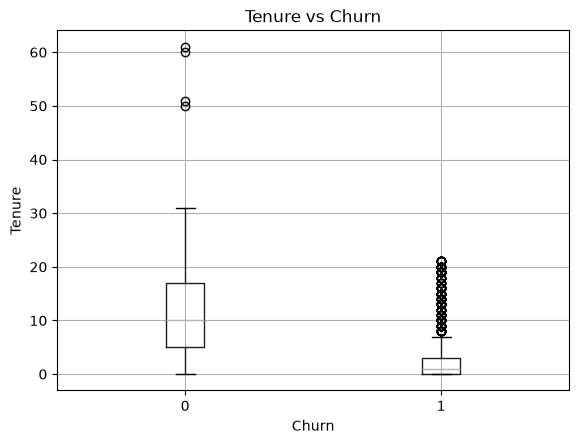

In [28]:
df.boxplot(column="Tenure", by="Churn")

plt.title("Tenure vs Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure")

plt.show()

In [29]:
df.groupby("Churn")["DaySinceLastOrder"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
0,4429,4.807406,4.0,0.0,31.0
1,894,3.236018,2.0,0.0,46.0


In [30]:
df.groupby("Churn")["OrderCount"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
0,4442,3.046601,2.0,1.0,16.0
1,930,2.823656,2.0,1.0,16.0


In [31]:
df.groupby("Churn")["WarehouseToHome"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
0,4515,15.353931,13.0,5.0,127.0
1,864,17.134259,15.0,5.0,36.0


In [32]:
df.groupby("Churn")["HourSpendOnApp"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
0,4485,2.925530,3.0,0.0,5.0
1,890,2.961798,3.0,2.0,4.0


In [33]:
df.groupby("Churn")["CouponUsed"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
0,4434,1.758232,1.0,0.0,16.0
1,940,1.717021,1.0,0.0,16.0


In [34]:
df.groupby("Churn")["OrderAmountHikeFromlastYear"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
0,4431,15.724893,15.0,11.0,26.0
1,934,15.627409,14.0,11.0,26.0


In [35]:
df.groupby("Churn")["CashbackAmount"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
0,4682,180.635203,166.115,0.00,324.99
1,948,160.370928,149.660,110.09,323.59


In [36]:
df.groupby("Churn")["NumberOfDeviceRegistered"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
0,4682,3.639257,4.0,1,6
1,948,3.934599,4.0,1,6


In [37]:
df.groupby("Churn")["NumberOfAddress"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
0,4682,4.162965,3.0,1,22
1,948,4.466245,3.0,1,20


In [38]:
correlation = df.select_dtypes(include="number").corr()

correlation

,CustomerID,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
CustomerID,1.000000,-0.019083,0.029952,0.003239,0.058909,0.598417,0.411098,-0.033146,0.160814,-0.009944,0.117243,0.234302,0.139008,0.113243,0.217129
Churn,-0.019083,1.000000,-0.349408,0.084703,0.076630,0.018675,0.107939,0.105481,0.043931,0.250188,-0.010058,-0.008264,-0.028697,-0.160757,-0.154118
Tenure,0.029952,-0.349408,1.000000,-0.060688,-0.018218,-0.021226,-0.023983,-0.013903,0.237666,-0.021268,0.005825,0.129035,0.186403,0.184552,0.476380
CityTier,0.003239,0.084703,-0.060688,1.000000,0.010624,-0.009150,0.027934,-0.011554,-0.029440,0.003375,-0.031408,0.021456,0.033388,0.017525,0.055746
WarehouseToHome,0.058909,0.076630,-0.018218,0.010624,1.000000,0.060990,0.019071,0.007722,-0.011020,0.028696,0.038795,-0.003935,0.002681,0.017829,-0.009200
HourSpendOnApp,0.598417,0.018675,-0.021226,-0.009150,0.060990,1.000000,0.316800,0.031858,0.145126,0.006976,0.106843,0.191528,0.109575,0.075716,0.121490
NumberOfDeviceRegistered,0.411098,0.107939,-0.023983,0.027934,0.019071,0.316800,1.000000,-0.017228,0.084997,0.003407,0.069475,0.151685,0.103464,0.018208,0.137183
SatisfactionScore,-0.033146,0.105481,-0.013903,-0.011554,0.007722,0.031858,-0.017228,1.000000,0.053583,-0.031115,-0.027730,0.017936,0.019764,0.032082,0.003473
NumberOfAddress,0.160814,0.043931,0.237666,-0.029440,-0.011020,0.145126,0.084997,0.053583,1.000000,-0.026399,0.015533,0.042120,-0.007609,-0.064847,0.186688
Complain,-0.009944,0.250188,-0.021268,0.003375,0.028696,0.006976,0.003407,-0.031115,-0.026399,1.000000,-0.004529,-0.008174,-0.019307,-0.043546,0.000525


In [39]:
# Create a separate working copy
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (5630, 20)
Working dataset shape: (5630, 20)


In [40]:
missing = df_clean.isnull().sum()

missing[missing > 0].sort_values(ascending=False)

DaySinceLastOrder              307
OrderAmountHikeFromlastYear    265
Tenure                         264
OrderCount                     258
CouponUsed                     256
HourSpendOnApp                 255
WarehouseToHome                251
dtype: int64

In [41]:
df_clean.dtypes

CustomerID                       int64
Churn                            int64
Tenure                         float64
PreferredLoginDevice               str
CityTier                         int64
WarehouseToHome                float64
PreferredPaymentMode               str
Gender                             str
HourSpendOnApp                 float64
NumberOfDeviceRegistered         int64
PreferedOrderCat                   str
SatisfactionScore                int64
MaritalStatus                      str
NumberOfAddress                  int64
Complain                         int64
OrderAmountHikeFromlastYear    float64
CouponUsed                     float64
OrderCount                     float64
DaySinceLastOrder              float64
CashbackAmount                 float64
dtype: object

In [42]:
y = df_clean["Churn"]

In [43]:
categorical_columns = df_clean.select_dtypes(
    include=["str", "object", "category"]
).columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df_clean[col].value_counts(dropna=False))


PreferredLoginDevice
PreferredLoginDevice
Mobile Phone    2765
Computer        1634
Phone           1231
Name: count, dtype: int64

PreferredPaymentMode
PreferredPaymentMode
Debit Card          2314
Credit Card         1501
E wallet             614
UPI                  414
COD                  365
CC                   273
Cash on Delivery     149
Name: count, dtype: int64

Gender
Gender
Male      3384
Female    2246
Name: count, dtype: int64

PreferedOrderCat
PreferedOrderCat
Laptop & Accessory    2050
Mobile Phone          1271
Fashion                826
Mobile                 809
Grocery                410
Others                 264
Name: count, dtype: int64

MaritalStatus
MaritalStatus
Married     2986
Single      1796
Divorced     848
Name: count, dtype: int64


In [44]:
data_dict = pd.read_excel(
    "E Commerce Dataset.xlsx",
    sheet_name="Data Dict"
)

print(data_dict.to_string(index=False))

 Unnamed: 0 Unnamed: 1                  Unnamed: 2                                                    Unnamed: 3
        NaN       Data                    Variable                                                   Discerption
        NaN     E Comm                  CustomerID                                            Unique customer ID
        NaN     E Comm                       Churn                                                    Churn Flag
        NaN     E Comm                      Tenure                            Tenure of customer in organization
        NaN     E Comm        PreferredLoginDevice                            Preferred login device of customer
        NaN     E Comm                    CityTier                                                     City tier
        NaN     E Comm             WarehouseToHome             Distance in between warehouse to home of customer
        NaN     E Comm        PreferredPaymentMode                          Preferred payment me

In [45]:
print("Login Device Categories:")
print(df_clean["PreferredLoginDevice"].value_counts())

print("\nPayment Mode Categories:")
print(df_clean["PreferredPaymentMode"].value_counts())

Login Device Categories:
PreferredLoginDevice
Mobile Phone    2765
Computer        1634
Phone           1231
Name: count, dtype: int64

Payment Mode Categories:
PreferredPaymentMode
Debit Card          2314
Credit Card         1501
E wallet             614
UPI                  414
COD                  365
CC                   273
Cash on Delivery     149
Name: count, dtype: int64


In [46]:
# Input features: information used to predict churn
X = df_clean.drop(columns=["CustomerID", "Churn"])

# Target: what we want to predict
y = df_clean["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (5630, 18)
Target shape: (5630,)

Target distribution:
Churn
0    4682
1     948
Name: count, dtype: int64


In [47]:
# Count rows containing at least one missing value
rows_with_missing = df_clean.isnull().any(axis=1).sum()

# Count rows containing no missing values
rows_without_missing = df_clean.notnull().all(axis=1).sum()

print("Total rows:", len(df_clean))
print("Rows with missing values:", rows_with_missing)
print("Rows without missing values:", rows_without_missing)

Total rows: 5630
Rows with missing values: 1856
Rows without missing values: 3774


In [48]:
missing_by_churn = df_clean.groupby("Churn").apply(
    lambda group: group.isnull().sum()
)

print(missing_by_churn.T)


Churn                          0   1
CustomerID                     0   0
Tenure                       183  81
PreferredLoginDevice           0   0
CityTier                       0   0
WarehouseToHome              167  84
PreferredPaymentMode           0   0
Gender                         0   0
HourSpendOnApp               197  58
NumberOfDeviceRegistered       0   0
PreferedOrderCat               0   0
SatisfactionScore              0   0
MaritalStatus                  0   0
NumberOfAddress                0   0
Complain                       0   0
OrderAmountHikeFromlastYear  251  14
CouponUsed                   248   8
OrderCount                   240  18
DaySinceLastOrder            253  54
CashbackAmount                 0   0


In [49]:
for col in [
    "PreferredLoginDevice",
    "PreferredPaymentMode",
    "PreferedOrderCat"
]:
    print(f"\n{col}")
    print(df_clean[col].value_counts(dropna=False))


PreferredLoginDevice
PreferredLoginDevice
Mobile Phone    2765
Computer        1634
Phone           1231
Name: count, dtype: int64

PreferredPaymentMode
PreferredPaymentMode
Debit Card          2314
Credit Card         1501
E wallet             614
UPI                  414
COD                  365
CC                   273
Cash on Delivery     149
Name: count, dtype: int64

PreferedOrderCat
PreferedOrderCat
Laptop & Accessory    2050
Mobile Phone          1271
Fashion                826
Mobile                 809
Grocery                410
Others                 264
Name: count, dtype: int64


In [50]:
# Count rows containing at least one missing value
rows_with_missing = df_clean.isnull().any(axis=1).sum()

# Count rows containing no missing values
rows_without_missing = df_clean.notnull().all(axis=1).sum()

print("Total rows:", len(df_clean))
print("Rows with missing values:", rows_with_missing)
print("Rows without missing values:", rows_without_missing)

Total rows: 5630
Rows with missing values: 1856
Rows without missing values: 3774


In [51]:
print("Missing target values:", df_clean["Churn"].isnull().sum())

print("\nTarget distribution:")
print(df_clean["Churn"].value_counts(dropna=False))

Missing target values: 0

Target distribution:
Churn
0    4682
1     948
Name: count, dtype: int64


# Splitting data

In [52]:
%pip install scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [53]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df_clean.drop(columns=["CustomerID", "Churn"])
y = df_clean["Churn"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (4504, 18)
Testing features: (1126, 18)


In [54]:
# Identify categorical columns
categorical_columns = X_train.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

# Identify numerical columns
numerical_columns = X_train.select_dtypes(
    include="number"
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']

Categorical columns:
['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']


In [55]:
## imporataint 

In [56]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Process numerical features
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical features
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [57]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Combine preprocessing and the ML model
model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

print("Complete ML pipeline created successfully.")

Complete ML pipeline created successfully.


In [58]:
# Train the complete pipeline
model_pipeline.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [59]:
# Predict churn labels for unseen customers
y_pred = model_pipeline.predict(X_test)

# Predict churn probabilities
y_prob = model_pipeline.predict_proba(X_test)[:, 1]

print("Actual labels:")
print(y_test.head(10).tolist())

print("\nPredicted labels:")
print(y_pred[:10].tolist())

print("\nPredicted churn probabilities:")
print(y_prob[:10].round(3).tolist())

Actual labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Predicted labels:
[0, 0, 0, 0, 1, 0, 0, 0, 0, 0]

Predicted churn probabilities:
[0.016, 0.101, 0.037, 0.052, 0.866, 0.005, 0.204, 0.013, 0.428, 0.019]


Confusion Matrix:
[[730 206]
 [ 30 160]]


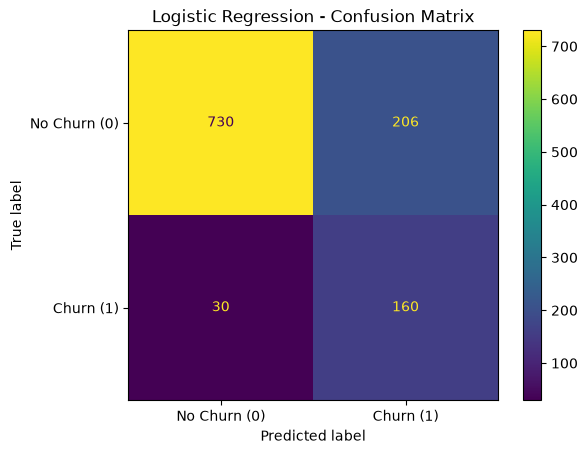

In [60]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize the results
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn (0)", "Churn (1)"]
)

display.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [61]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

Accuracy: 0.7904

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.78      0.86       936
           1       0.44      0.84      0.58       190

    accuracy                           0.79      1126
   macro avg       0.70      0.81      0.72      1126
weighted avg       0.87      0.79      0.81      1126

ROC-AUC: 0.8862


In [62]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Reuse the same preprocessing configuration
unweighted_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train without class weighting
unweighted_pipeline.fit(X_train, y_train)

# Generate predictions
y_pred_unweighted = unweighted_pipeline.predict(X_test)
y_prob_unweighted = unweighted_pipeline.predict_proba(X_test)[:, 1]

print("Unweighted Logistic Regression trained successfully.")

Unweighted Logistic Regression trained successfully.


In [63]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Churn Precision": precision_score(y_true, y_pred, zero_division=0),
        "Churn Recall": recall_score(y_true, y_pred, zero_division=0),
        "Churn F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

results = [
    evaluate_model(
        "Logistic Regression (Balanced)",
        y_test,
        y_pred,
        y_prob
    ),
    evaluate_model(
        "Logistic Regression (Unweighted)",
        y_test,
        y_pred_unweighted,
        y_prob_unweighted
    )
]

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

                           Model  Accuracy  Churn Precision  Churn Recall  Churn F1  ROC-AUC
  Logistic Regression (Balanced)    0.7904           0.4372        0.8421    0.5755   0.8862
Logistic Regression (Unweighted)    0.8881           0.7424        0.5158    0.6087   0.8858


In [64]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score
       0.3     0.3406  0.9105    0.4957
       0.4     0.3935  0.8947    0.5466
       0.5     0.4372  0.8421    0.5755
       0.6     0.5033  0.8000    0.6179
       0.7     0.5751  0.7053    0.6336


In [65]:
from sklearn.metrics import confusion_matrix

# Predictions at threshold 0.5
pred_05 = (y_prob >= 0.5).astype(int)

# Predictions at threshold 0.7
pred_07 = (y_prob >= 0.7).astype(int)

print("Confusion Matrix — Threshold 0.5")
print(confusion_matrix(y_test, pred_05))

print("\nConfusion Matrix — Threshold 0.7")
print(confusion_matrix(y_test, pred_07))

Confusion Matrix — Threshold 0.5
[[730 206]
 [ 30 160]]

Confusion Matrix — Threshold 0.7
[[837  99]
 [ 56 134]]


In [66]:
# Moving to Random Forest


In [67]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

In [68]:
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [69]:
random_forest_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['Tenure','PreferredLoginDevice','CityTier',...,'OrderCount', 'DaySinceLastOrder','CashbackAmount']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).

In [70]:
# Predict customer classes: 0 = No Churn, 1 = Churn
y_pred_rf = random_forest_pipeline.predict(X_test)

# Predict the probability of churn
y_prob_rf = random_forest_pipeline.predict_proba(X_test)[:, 1]

print("First 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred_rf[:10].tolist())

print("\nFirst 10 churn probabilities:")
print(y_prob_rf[:10].round(3).tolist())

First 10 actual labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

First 10 predicted labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

First 10 churn probabilities:
[0.015, 0.095, 0.03, 0.045, 0.085, 0.025, 0.1, 0.0, 0.13, 0.04]


In [71]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Random Forest Evaluation")
print("-" * 35)

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_rf), 4))

print("Churn Precision:",
      round(precision_score(y_test, y_pred_rf), 4))

print("Churn Recall:",
      round(recall_score(y_test, y_pred_rf), 4))

print("Churn F1-score:",
      round(f1_score(y_test, y_pred_rf), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Evaluation
-----------------------------------
Accuracy: 0.9822
Churn Precision: 0.9337
Churn Recall: 0.9632
Churn F1-score: 0.9482
ROC-AUC: 0.9984

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       936
           1       0.93      0.96      0.95       190

    accuracy                           0.98      1126
   macro avg       0.96      0.97      0.97      1126
weighted avg       0.98      0.98      0.98      1126



In [72]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm_rf)

Random Forest Confusion Matrix:
[[923  13]
 [  7 183]]


In [73]:
# Get the fitted preprocessing component
fitted_preprocessor = random_forest_pipeline.named_steps["preprocessor"]

# Get the names of the transformed features
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Random Forest feature importance scores
importances = random_forest_pipeline.named_steps[
    "classifier"
].feature_importances_

# Create a table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Display the 15 most important features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15).to_string(index=False))

                                         Feature  Importance
                               numerical__Tenure    0.240984
                       numerical__CashbackAmount    0.091616
                             numerical__Complain    0.064492
                      numerical__WarehouseToHome    0.060438
                    numerical__DaySinceLastOrder    0.056561
                      numerical__NumberOfAddress    0.050603
          numerical__OrderAmountHikeFromlastYear    0.049838
                    numerical__SatisfactionScore    0.046817
             numerical__NumberOfDeviceRegistered    0.031723
                           numerical__OrderCount    0.027763
                             numerical__CityTier    0.026553
                           numerical__CouponUsed    0.023417
               categorical__MaritalStatus_Single    0.023194
categorical__PreferedOrderCat_Laptop & Accessory    0.018868
              categorical__MaritalStatus_Married    0.014939


In [74]:
tenure_summary = (
    X_train.assign(Churn=y_train)
    .groupby("Churn")["Tenure"]
    .agg(["count", "mean", "median", "min", "max"])
)

print(tenure_summary)

       count       mean  median  min   max
Churn                                     
0       3597  11.511815    10.0  0.0  61.0
1        694   3.317003     1.0  0.0  21.0


In [75]:
from sklearn.metrics import roc_auc_score

# Use tenure alone, treating lower tenure as a higher churn risk
tenure_score = -X_test["Tenure"].fillna(
    X_train["Tenure"].median()
)

tenure_auc = roc_auc_score(y_test, tenure_score)

print("ROC-AUC using tenure alone:", round(tenure_auc, 4))

ROC-AUC using tenure alone: 0.787


In [76]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_auc = cross_val_score(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("ROC-AUC for each fold:", cv_auc.round(4))
print("Mean ROC-AUC:", round(cv_auc.mean(), 4))
print("Standard deviation:", round(cv_auc.std(), 4))

ROC-AUC for each fold: [0.9872 0.9776 0.9725 0.9752 0.9715]
Mean ROC-AUC: 0.9768
Standard deviation: 0.0056


In [77]:
# Calculate the correlation of each numeric feature with Churn
churn_correlations = (
    df_clean
    .drop(columns=["CustomerID"])
    .corr(numeric_only=True)["Churn"]
    .drop("Churn")
    .sort_values(key=abs, ascending=False)
)

print(churn_correlations.round(4).to_string())

Tenure                        -0.3494
Complain                       0.2502
DaySinceLastOrder             -0.1608
CashbackAmount                -0.1541
NumberOfDeviceRegistered       0.1079
SatisfactionScore              0.1055
CityTier                       0.0847
WarehouseToHome                0.0766
NumberOfAddress                0.0439
OrderCount                    -0.0287
HourSpendOnApp                 0.0187
OrderAmountHikeFromlastYear   -0.0101
CouponUsed                    -0.0083


In [78]:
data_dict = pd.read_excel(
    "E Commerce Dataset.xlsx",
    sheet_name="Data Dict"
)

print(data_dict.to_string(index=False))

 Unnamed: 0 Unnamed: 1                  Unnamed: 2                                                    Unnamed: 3
        NaN       Data                    Variable                                                   Discerption
        NaN     E Comm                  CustomerID                                            Unique customer ID
        NaN     E Comm                       Churn                                                    Churn Flag
        NaN     E Comm                      Tenure                            Tenure of customer in organization
        NaN     E Comm        PreferredLoginDevice                            Preferred login device of customer
        NaN     E Comm                    CityTier                                                     City tier
        NaN     E Comm             WarehouseToHome             Distance in between warehouse to home of customer
        NaN     E Comm        PreferredPaymentMode                          Preferred payment me

In [79]:
tenure_churn = (
    df_clean
    .dropna(subset=["Tenure"])
    .groupby("Tenure")["Churn"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "ChurnRate"})
)

tenure_churn["ChurnRate"] *= 100

print(tenure_churn.head(15).round(2))

        count  ChurnRate
Tenure                  
0.0       508      53.54
1.0       690      50.58
2.0       167       8.38
3.0       195       9.23
4.0       203       9.85
5.0       204       7.84
6.0       183       4.37
7.0       221       7.24
8.0       263       6.08
9.0       247       4.86
10.0      213       6.57
11.0      194       5.15
12.0      182       3.85
13.0      181       7.18
14.0      176       7.95


In [80]:
test_tenure_churn = (
    X_test.assign(Churn=y_test)
    .dropna(subset=["Tenure"])
    .groupby("Tenure")["Churn"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "ChurnRate"})
)

test_tenure_churn["ChurnRate"] *= 100

print(test_tenure_churn.head(15).round(2))

        count  ChurnRate
Tenure                  
0.0        95      52.63
1.0       129      53.49
2.0        40      12.50
3.0        41       9.76
4.0        58      13.79
5.0        38       7.89
6.0        28       3.57
7.0        42       4.76
8.0        53       5.66
9.0        58       3.45
10.0       34       5.88
11.0       35       2.86
12.0       41       2.44
13.0       37       2.70
14.0       41       7.32


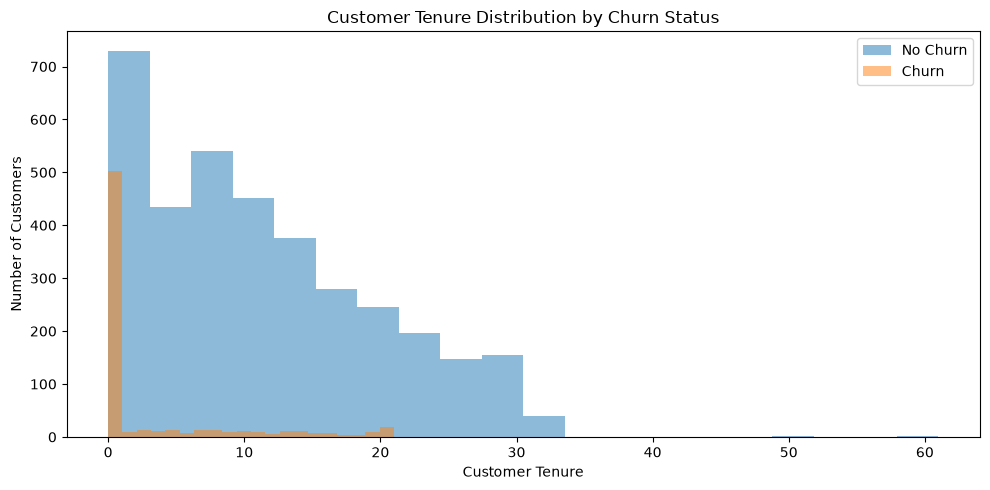

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for churn_value, label in [(0, "No Churn"), (1, "Churn")]:
    tenure_values = X_train.loc[
        y_train == churn_value, "Tenure"
    ].dropna()

    plt.hist(
        tenure_values,
        bins=20,
        alpha=0.5,
        label=label
    )

plt.xlabel("Customer Tenure")
plt.ylabel("Number of Customers")
plt.title("Customer Tenure Distribution by Churn Status")
plt.legend()
plt.tight_layout()
plt.show()

In [82]:
complain_churn = (
    df_clean
    .groupby("Complain")["Churn"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "ChurnRate"})
)

complain_churn["ChurnRate"] *= 100

print(complain_churn.round(2))

          count  ChurnRate
Complain                  
0          4026      10.93
1          1604      31.67


In [83]:
category_churn = (
    df_clean
    .groupby("PreferedOrderCat")["Churn"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "ChurnRate"})
)

category_churn["ChurnRate"] *= 100

print(category_churn.sort_values(
    "ChurnRate",
    ascending=False
).round(2))

                    count  ChurnRate
PreferedOrderCat                    
Mobile Phone         1271      27.54
Mobile                809      27.19
Fashion               826      15.50
Laptop & Accessory   2050      10.24
Others                264       7.58
Grocery               410       4.88


In [84]:
# Remove Tenure from the training and test features
X_train_no_tenure = X_train.drop(columns=["Tenure"])
X_test_no_tenure = X_test.drop(columns=["Tenure"])

# Update the numerical feature list
numerical_columns_no_tenure = [
    col for col in numerical_columns
    if col != "Tenure"
]

print("Original number of features:", X_train.shape[1])
print("Features without Tenure:", X_train_no_tenure.shape[1])
print("Numerical features remaining:", len(numerical_columns_no_tenure))
print("Categorical features remaining:", len(categorical_columns))

Original number of features: 18
Features without Tenure: 17
Numerical features remaining: 12
Categorical features remaining: 5


In [85]:
# Create a fresh preprocessing pipeline
preprocessor_no_tenure = ColumnTransformer(
    transformers=[
        (
            "numerical",
            clone(numerical_pipeline),
            numerical_columns_no_tenure
        ),
        (
            "categorical",
            clone(categorical_pipeline),
            categorical_columns
        )
    ]
)

# Create the Random Forest pipeline
rf_no_tenure = Pipeline(steps=[
    ("preprocessor", preprocessor_no_tenure),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model without Tenure
rf_no_tenure.fit(X_train_no_tenure, y_train)

print("Random Forest without Tenure trained successfully.")

Random Forest without Tenure trained successfully.


In [86]:
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score

# Generate predictions without Tenure
y_pred_no_tenure = rf_no_tenure.predict(X_test_no_tenure)

# Get churn probabilities
y_prob_no_tenure = rf_no_tenure.predict_proba(
    X_test_no_tenure
)[:, 1]

# Evaluate the model
print("Random Forest WITHOUT Tenure")
print("-" * 35)

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_no_tenure), 4))

print("Churn Precision:",
      round(precision_score(y_test, y_pred_no_tenure), 4))

print("Churn Recall:",
      round(recall_score(y_test, y_pred_no_tenure), 4))

print("Churn F1-score:",
      round(f1_score(y_test, y_pred_no_tenure), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_no_tenure), 4))

Random Forest WITHOUT Tenure
-----------------------------------
Accuracy: 0.968
Churn Precision: 0.9185
Churn Recall: 0.8895
Churn F1-score: 0.9037
ROC-AUC: 0.9887


In [87]:
feature_names_no_tenure = (
    rf_no_tenure
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances_no_tenure = (
    rf_no_tenure
    .named_steps["classifier"]
    .feature_importances_
)

importance_no_tenure_df = pd.DataFrame({
    "Feature": feature_names_no_tenure,
    "Importance": importances_no_tenure
}).sort_values(
    "Importance",
    ascending=False
)

print(importance_no_tenure_df.head(15).to_string(index=False))

                                         Feature  Importance
                       numerical__CashbackAmount    0.120213
                      numerical__WarehouseToHome    0.084049
                             numerical__Complain    0.078706
                    numerical__DaySinceLastOrder    0.075611
          numerical__OrderAmountHikeFromlastYear    0.069459
                      numerical__NumberOfAddress    0.062928
                    numerical__SatisfactionScore    0.062792
             numerical__NumberOfDeviceRegistered    0.042550
                           numerical__OrderCount    0.037777
                             numerical__CityTier    0.033167
               categorical__MaritalStatus_Single    0.031122
                           numerical__CouponUsed    0.029344
categorical__PreferedOrderCat_Laptop & Accessory    0.023657
                       numerical__HourSpendOnApp    0.020719
      categorical__PreferedOrderCat_Mobile Phone    0.019853


In [88]:
from sklearn.metrics import roc_auc_score

# Training-set predictions
y_prob_rf_train = random_forest_pipeline.predict_proba(X_train)[:, 1]

# Compare training and test ROC-AUC
train_auc = roc_auc_score(y_train, y_prob_rf_train)
test_auc = roc_auc_score(y_test, y_prob_rf)

print("Training ROC-AUC:", round(train_auc, 4))
print("Test ROC-AUC:", round(test_auc, 4))
print("Difference:", round(train_auc - test_auc, 4))

Training ROC-AUC: 1.0
Test ROC-AUC: 0.9984
Difference: 0.0016


In [89]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

rf_threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob_rf >= threshold).astype(int)

    rf_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        )
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

print(rf_threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score
       0.3     0.7143  1.0000    0.8333
       0.4     0.8400  0.9947    0.9108
       0.5     0.9340  0.9684    0.9509
       0.6     0.9825  0.8842    0.9307
       0.7     1.0000  0.8053    0.8921


In [90]:
from sklearn.inspection import permutation_importance

In [91]:
permutation_result = permutation_importance(
    random_forest_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

In [92]:
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance Mean",
    ascending=False
)

print(importance_df.round(4).to_string(index=False))

                    Feature  Importance Mean  Importance Std
                     Tenure           0.1068          0.0037
                   Complain           0.0330          0.0022
              MaritalStatus           0.0125          0.0007
           PreferedOrderCat           0.0096          0.0010
            NumberOfAddress           0.0075          0.0007
             CashbackAmount           0.0053          0.0007
          SatisfactionScore           0.0051          0.0004
          DaySinceLastOrder           0.0050          0.0004
       PreferredPaymentMode           0.0046          0.0006
                   CityTier           0.0036          0.0007
       PreferredLoginDevice           0.0035          0.0003
            WarehouseToHome           0.0027          0.0008
                 OrderCount           0.0026          0.0001
                     Gender           0.0022          0.0002
OrderAmountHikeFromlastYear           0.0021          0.0003
   NumberOfDeviceRegiste

In [93]:
tenure_churn = (
    df.groupby("Tenure", dropna=False)
      .agg(
          Customers=("Churn", "size"),
          Churn_Rate=("Churn", "mean")
      )
      .reset_index()
)

tenure_churn["Churn_Rate"] *= 100

tenure_churn = tenure_churn.sort_values("Tenure")

print(tenure_churn.head(15).round(2).to_string(index=False))

 Tenure  Customers  Churn_Rate
    0.0        508       53.54
    1.0        690       50.58
    2.0        167        8.38
    3.0        195        9.23
    4.0        203        9.85
    5.0        204        7.84
    6.0        183        4.37
    7.0        221        7.24
    8.0        263        6.08
    9.0        247        4.86
   10.0        213        6.57
   11.0        194        5.15
   12.0        182        3.85
   13.0        181        7.18
   14.0        176        7.95


In [94]:
tenure_churn_counts = (
    df.groupby("Tenure", dropna=False)
      .agg(
          Customers=("Churn", "size"),
          Churners=("Churn", "sum"),
          Churn_Rate=("Churn", "mean")
      )
      .reset_index()
)

tenure_churn_counts["Non_Churners"] = (
    tenure_churn_counts["Customers"]
    - tenure_churn_counts["Churners"]
)

tenure_churn_counts["Churn_Rate"] *= 100

print(
    tenure_churn_counts[
        ["Tenure", "Customers", "Churners",
         "Non_Churners", "Churn_Rate"]
    ].head(15).round(2).to_string(index=False)
)

 Tenure  Customers  Churners  Non_Churners  Churn_Rate
    0.0        508       272           236       53.54
    1.0        690       349           341       50.58
    2.0        167        14           153        8.38
    3.0        195        18           177        9.23
    4.0        203        20           183        9.85
    5.0        204        16           188        7.84
    6.0        183         8           175        4.37
    7.0        221        16           205        7.24
    8.0        263        16           247        6.08
    9.0        247        12           235        4.86
   10.0        213        14           199        6.57
   11.0        194        10           184        5.15
   12.0        182         7           175        3.85
   13.0        181        13           168        7.18
   14.0        176        14           162        7.95


In [95]:
complaint_tenure_analysis = (
    df.groupby(["Tenure", "Complain"], dropna=False)
      .agg(
          Customers=("Churn", "size"),
          Churners=("Churn", "sum"),
          Churn_Rate=("Churn", "mean")
      )
      .reset_index()
)

complaint_tenure_analysis["Churn_Rate"] *= 100

print(
    complaint_tenure_analysis[
        ["Tenure", "Complain", "Customers", "Churners", "Churn_Rate"]
    ]
    .query("Tenure <= 5")
    .round(2)
    .to_string(index=False)
)

 Tenure  Complain  Customers  Churners  Churn_Rate
    0.0         0        314       133       42.36
    0.0         1        194       139       71.65
    1.0         0        438       163       37.21
    1.0         1        252       186       73.81
    2.0         0        135         6        4.44
    2.0         1         32         8       25.00
    3.0         0        151         6        3.97
    3.0         1         44        12       27.27
    4.0         0        147         6        4.08
    4.0         1         56        14       25.00
    5.0         0        156         6        3.85
    5.0         1         48        10       20.83


In [96]:
# # Business Insights and Recommendations

# ## 1. Early-Tenure Customer Churn

# ### Finding
# Customers with tenure 0 and 1 have observed churn rates of 53.54%
# and 50.58%, respectively.

# Together, these groups contain 621 churners out of 1,198 customers,
# representing approximately 65.51% of all churners in the dataset.

# ### Business implication
# Early-tenure customers represent a high-priority group for further
# investigation.

# ### Recommendation
# Investigate the initial customer experience, including onboarding,
# first-order satisfaction, delivery experience, and customer support.

# ---

# # ## 2. Customer Complaints and Churn

# # ### Finding
# # Customers who complained have an observed churn rate of 31.67%,
# # compared with 10.93% among customers who did not complain.

# # The association remains visible within several tenure groups.

# # ### Business implication
# # Complaint status may provide useful information for identifying
# # customers who warrant additional attention.

# # ### Recommendation
# # Investigate complaint resolution processes and evaluate whether
# # appropriate follow-up can improve customer retention.

# # ---

# ## 3. Combining Tenure and Complaint Information

# ### Finding
# # Customers with tenure 1 who complained have an observed churn rate
# # of 73.81% (186 churners out of 252 customers).

# # ### Business implication
# # Combining customer characteristics may help identify groups that
# # deserve closer investigation.

# # ### Recommendation
# # Consider prioritizing these customers for a retention review,
# # subject to validation of the proposed approach.

# ---

# ## 4. Important Limitations

# # - These findings describe associations in the available dataset.
# # - They do not establish that any feature causes churn.
# # - Group churn rates are not guarantees of individual outcomes.
# # - The dataset documentation does not establish when churn labels
# #   were assigned relative to feature measurements.
# # - Therefore, reliable future-churn prediction has not yet been
# #   established.
# # - The proposed retention actions must be evaluated before claiming
# #   that they reduce churn.

In [97]:
# # Model Comparison and Evaluation

# ## Logistic Regression

# The balanced Logistic Regression model achieved a test ROC-AUC
# of 0.8862.

# It identified many churners but produced more false-positive
# predictions than the Random Forest.

# ## Random Forest

# The Random Forest achieved a test ROC-AUC of 0.9984.

# Its test-set confusion matrix at the default threshold of 0.5 was:

# | | Predicted: No Churn | Predicted: Churn |
# |---|---:|---:|
# | Actual: No Churn | 923 | 13 |
# | Actual: Churn | 7 | 183 |

# The model performed extremely well on the available test data.
# However, this unusually strong result requires cautious interpretation.

# ## Validation and Limitations

# - Five-fold cross-validation produced a mean ROC-AUC of 0.9768.
# - Removing Tenure reduced the Random Forest test ROC-AUC to 0.9887.
# - The dataset documentation does not establish the timing of the
#   churn labels relative to the input features.
# - Future-churn prediction has therefore not been conclusively
#   established.
# - We explored thresholds on the test set, so those results should
#   not be treated as an unbiased final threshold-selection evaluation.
# - A future version should use validation data or training-based
#   cross-validation for model and threshold selection, reserving a
#   final test set for evaluation.

In [98]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nROC-AUC:")
print(roc_auc_score(y_test, y_prob))


Confusion Matrix:
[[730 206]
 [ 30 160]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.78      0.86       936
           1       0.44      0.84      0.58       190

    accuracy                           0.79      1126
   macro avg       0.70      0.81      0.72      1126
weighted avg       0.87      0.79      0.81      1126


ROC-AUC:
0.8862235717498875


In [99]:
y_pred_rf = random_forest_pipeline.predict(X_test)
y_prob_rf = random_forest_pipeline.predict_proba(X_test)[:, 1]

print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nRandom Forest ROC-AUC:")
print(roc_auc_score(y_test, y_prob_rf))

Random Forest Confusion Matrix:
[[923  13]
 [  7 183]]

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       936
           1       0.93      0.96      0.95       190

    accuracy                           0.98      1126
   macro avg       0.96      0.97      0.97      1126
weighted avg       0.98      0.98      0.98      1126


Random Forest ROC-AUC:
0.9983861898335582


In [100]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7904,0.4372,0.8421,0.5755,0.8862
1,Random Forest,0.9822,0.9337,0.9632,0.9482,0.9984


In [101]:
import joblib

model_path = "random_forest_churn_pipeline.joblib"

joblib.dump(random_forest_pipeline, model_path)

print(f"Model saved successfully: {model_path}")

Model saved successfully: random_forest_churn_pipeline.joblib


In [102]:
loaded_model = joblib.load(model_path)

predictions_loaded = loaded_model.predict(X_test)

print(
    "Predictions match:",
    (predictions_loaded == y_pred_rf).all()
)

Predictions match: True


In [103]:
def predict_customer_churn(customer_data, model):
    """
    Predict churn for one customer.

    customer_data: Dictionary containing the customer's features.
    model: Trained preprocessing and Random Forest pipeline.
    """

    customer_df = pd.DataFrame([customer_data])

    prediction = model.predict(customer_df)[0]
    churn_probability = model.predict_proba(customer_df)[0][1]

    return {
        "predicted_churn": int(prediction),
        "churn_probability": round(float(churn_probability), 4)
    }

In [104]:
sample_customer = X_test.iloc[[0]]

sample_customer

,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
4006,17.0,Computer,3,9.0,Debit Card,Male,4.0,4,Laptop & Accessory,1,Married,3,0,21.0,6.0,8.0,8.0,181.75


In [105]:
customer_data = sample_customer.iloc[0].to_dict()

result = predict_customer_churn(
    customer_data,
    loaded_model
)

print(result)

{'predicted_churn': 0, 'churn_probability': 0.015}


In [106]:
from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_prob = random_forest_pipeline.predict_proba(X_test)[:, 1]
y_pred = random_forest_pipeline.predict(X_test)

print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

ROC-AUC: 0.9983861898335582

Confusion Matrix:
 [[923  13]
 [  7 183]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       936
           1       0.93      0.96      0.95       190

    accuracy                           0.98      1126
   macro avg       0.96      0.97      0.97      1126
weighted avg       0.98      0.98      0.98      1126



In [107]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTest target distribution:\n", y_test.value_counts())
print("\nModel:\n", random_forest_pipeline)
print("\nFeatures:\n", list(X.columns))

Scikit-learn version: 1.9.1
Training shape: (4504, 18)
Test shape: (1126, 18)

Test target distribution:
 Churn
0    936
1    190
Name: count, dtype: int64

Model:
 Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Tenure', 'CityTier',
                                                   'WarehouseToHome',
                                                   'HourSpendOnApp',
                                                   'NumberOfDeviceRegistered',
                                                   'SatisfactionScore',
                               

In [108]:
# Check how strongly each individual feature is associated
# with the churn target.

import pandas as pd

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

# Examine correlations for numerical features
df_check = X.copy()
df_check["Churn"] = y

print("Numerical feature correlations with Churn:")
print(
    df_check.corr(numeric_only=True)["Churn"]
    .drop("Churn")
    .sort_values(ascending=False)
)

print("\nTarget distribution:")
print(y.value_counts(normalize=True))

Numerical feature correlations with Churn:
Complain                       0.250188
NumberOfDeviceRegistered       0.107939
SatisfactionScore              0.105481
CityTier                       0.084703
WarehouseToHome                0.076630
NumberOfAddress                0.043931
HourSpendOnApp                 0.018675
CouponUsed                    -0.008264
OrderAmountHikeFromlastYear   -0.010058
OrderCount                    -0.028697
CashbackAmount                -0.154118
DaySinceLastOrder             -0.160757
Tenure                        -0.349408
Name: Churn, dtype: float64

Target distribution:
Churn
0    0.831616
1    0.168384
Name: proportion, dtype: float64


In [109]:
from IPython.display import display as show_table

print("Dataset shape:", df.shape)

print("\nChurn distribution:")
print(df["Churn"].value_counts())

print("\nDataset columns:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
show_table(df.head(10))

Dataset shape: (5630, 20)

Churn distribution:
Churn
0    4682
1     948
Name: count, dtype: int64

Dataset columns:
['CustomerID', 'Churn', 'Tenure', 'PreferredLoginDevice', 'CityTier', 'WarehouseToHome', 'PreferredPaymentMode', 'Gender', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']

First 10 rows:


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60
5,50006,1,0.0,Computer,1,22.0,Debit Card,Female,3.0,5,Mobile Phone,5,Single,2,1,22.0,4.0,6.0,7.0,139.19
6,50007,1,NaN,Phone,3,11.0,Cash on Delivery,Male,2.0,3,Laptop & Accessory,2,Divorced,4,0,14.0,0.0,1.0,0.0,120.86
7,50008,1,NaN,Phone,1,6.0,CC,Male,3.0,3,Mobile,2,Divorced,3,1,16.0,2.0,2.0,0.0,122.93
8,50009,1,13.0,Phone,3,9.0,E wallet,Male,NaN,4,Mobile,3,Divorced,2,1,14.0,0.0,1.0,2.0,126.83
9,50010,1,NaN,Phone,1,31.0,Debit Card,Male,2.0,5,Mobile,3,Single,2,0,12.0,1.0,1.0,1.0,122.93


In [110]:
# Compare average numerical feature values for churners vs non-churners

numeric_features = df.select_dtypes(include="number").columns.drop(
    ["CustomerID", "Churn"]
)

comparison = df.groupby("Churn")[numeric_features].mean().T
comparison.columns = ["No Churn (0)", "Churn (1)"]

comparison["Absolute Difference"] = (
    comparison["Churn (1)"] - comparison["No Churn (0)"]
).abs()

print(
    comparison.sort_values(
        "Absolute Difference", ascending=False
    ).round(2).to_string()
)

                             No Churn (0)  Churn (1)  Absolute Difference
CashbackAmount                     180.64     160.37                20.26
Tenure                              11.50       3.38                 8.12
WarehouseToHome                     15.35      17.13                 1.78
DaySinceLastOrder                    4.81       3.24                 1.57
SatisfactionScore                    3.00       3.39                 0.39
NumberOfAddress                      4.16       4.47                 0.30
Complain                             0.23       0.54                 0.30
NumberOfDeviceRegistered             3.64       3.93                 0.30
OrderCount                           3.05       2.82                 0.22
CityTier                             1.62       1.83                 0.21
OrderAmountHikeFromlastYear         15.72      15.63                 0.10
CouponUsed                           1.76       1.72                 0.04
HourSpendOnApp                       2

In [111]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

# Remove Tenure from the training and test data
X_train_no_tenure = X_train.drop(columns=["Tenure"])
X_test_no_tenure = X_test.drop(columns=["Tenure"])

# Rebuild the pipeline without Tenure
preprocessor_no_tenure = clone(preprocessor)

model_no_tenure = clone(rf_model)
model_no_tenure.set_params(preprocessor=preprocessor_no_tenure)

# Train and evaluate
model_no_tenure.fit(X_train_no_tenure, y_train)

y_proba_no_tenure = model_no_tenure.predict_proba(
    X_test_no_tenure
)[:, 1]

print(
    "ROC-AUC without Tenure:",
    round(roc_auc_score(y_test, y_proba_no_tenure), 4)
)

NameError: name 'rf_model' is not defined

In [ ]:
from sklearn.metrics import roc_auc_score

# Training ROC-AUC
train_probs = rf_model.predict_proba(X_train)[:, 1]
train_auc = roc_auc_score(y_train, train_probs)

# Test ROC-AUC
test_probs = rf_model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_probs)

print(f"Training ROC-AUC: {train_auc:.4f}")
print(f"Test ROC-AUC:     {test_auc:.4f}")
print(f"Difference:       {train_auc - test_auc:.4f}")

NameError: name 'rf_model' is not defined

In [ ]:
%whos

Variable                      Type                      Data/Info
-----------------------------------------------------------------
ColumnTransformer             ABCMeta                   <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
ConfusionMatrixDisplay        type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
LogisticRegression            type                      <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OneHotEncoder                 type                      <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Pipeline                      ABCMeta                   <class 'sklearn.pipeline.Pipeline'>
RandomForestClassifier        ABCMeta                   <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
SimpleImputer                 type                      <class 'sklearn.impute._base.SimpleImputer'>
StandardScaler                type                      <class 'sklearn.preproces<...>ng._data.StandardScaler'>
Str

In [ ]:
from sklearn.metrics import roc_auc_score

print("Training ROC-AUC:",
      roc_auc_score(y_train, y_prob_rf_train))

print("\nOther relevant variables:")
%whos

Training ROC-AUC: 1.0

Other relevant variables:
Variable                      Type                      Data/Info
-----------------------------------------------------------------
ColumnTransformer             ABCMeta                   <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
ConfusionMatrixDisplay        type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
LogisticRegression            type                      <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OneHotEncoder                 type                      <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Pipeline                      ABCMeta                   <class 'sklearn.pipeline.Pipeline'>
RandomForestClassifier        ABCMeta                   <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
SimpleImputer                 type                      <class 'sklearn.impute._base.SimpleImputer'>
StandardScaler                type                      <class 'sk

In [ ]:
# Check whether any CustomerIDs appear in both train and test sets

train_ids = set(df.loc[X_train.index, "CustomerID"])
test_ids = set(df.loc[X_test.index, "CustomerID"])

overlap = train_ids.intersection(test_ids)

print("Training customers:", len(train_ids))
print("Test customers:", len(test_ids))
print("Customers appearing in both:", len(overlap))

Training customers: 4504
Test customers: 1126
Customers appearing in both: 0
